# 03 - Feature Engineering: fitur kandidat dan dataset baseline (Issue #16)

**Tujuan:** menentukan target dan fitur untuk prediksi tarif sewa bulanan.

| Tugas di issue | Bagian notebook |
|---|---|
| Gunakan target `harga_bulanan_norm` | 2 |
| Pilih fitur fasilitas, ukuran, lantai, wilayah, jarak | 3 |
| Buat encoding fitur kategori | 4 |
| Gunakan hanya baris `model_ready` | 1 |
| Buat train-test split yang reproducible | 6 |
| Dokumentasikan alasan pemilihan fitur | 5 dan `models/model_card.md` |


In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error

sys.path.insert(0, str(Path('..') / 'models'))
import features_candidate as fc

# Urutan pencarian database; ubah bila lokasi berbeda
DB_CANDIDATES = [Path('../data/tobakost_survey_warehouse.db'), Path('../data/warehouse/tobakost_warehouse.db'), Path('../data/tobakost_warehouse.db')]
DB_PATH = next(p for p in DB_CANDIDATES if p.exists())
print('Database:', DB_PATH)

Database: ..\data\tobakost_warehouse.db


## 1. Muat data dan pilih baris `model_ready`

In [2]:
raw = fc.add_binary_flags(fc.load_warehouse(DB_PATH))
print('Baris setelah join:', raw.shape)
df = fc.select_model_ready(raw)
print('Baris dipakai untuk model:', len(df))
print('Nilai kosong per kolom (hanya yang ada):'); print(df.isna().sum()[df.isna().sum() > 0])

Baris setelah join: (600, 64)
Kolom model_ready tidak ada; memakai aturan: target > 0 dan fitur lengkap.
Baris siap model: 600 dari 600
Baris dipakai untuk model: 600
Nilai kosong per kolom (hanya yang ada):
Series([], dtype: int64)


## 2. Target: `harga_bulanan_norm`

count        600.0
mean      782000.0
std       175975.0
min       433333.0
25%       666667.0
50%       750000.0
75%       850000.0
max      1250000.0
Name: harga_bulanan_norm, dtype: float64
Skewness: 0.96


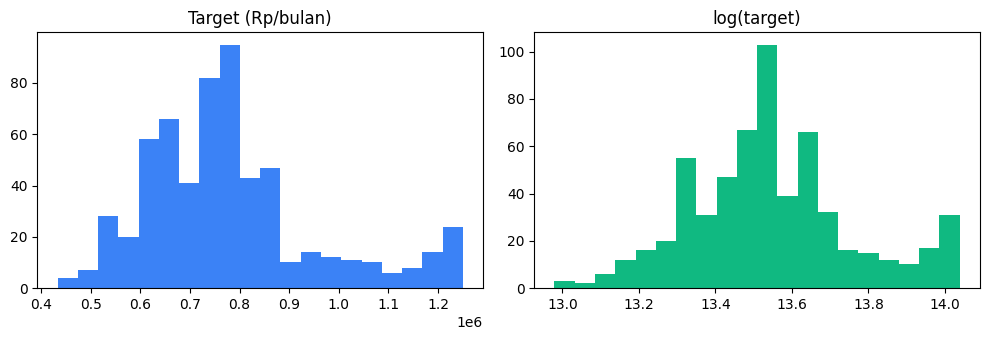

In [3]:
y = df[fc.TARGET]
print(y.describe().round(0))
print('Skewness:', round(y.skew(), 2))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].hist(y, bins=20, color='#3b82f6'); ax[0].set_title('Target (Rp/bulan)')
ax[1].hist(np.log(y), bins=20, color='#10b981'); ax[1].set_title('log(target)')
plt.tight_layout(); plt.show()

## 3. Fitur kandidat

Kelompok fitur sesuai issue: fasilitas, ukuran, lantai, wilayah, dan jarak.

In [4]:
for group, cols in fc.FEATURE_GROUPS.items():
    print(f'{group:26s} ({len(cols):2d}):', ', '.join(cols))
print()
print('Kolom yang TIDAK dipakai:')
pd.Series(fc.EXCLUDED_COLUMNS, name='alasan').to_frame()

ukuran dan lantai          ( 2): luas_kamar_m2, jumlah_lantai
aksesibilitas (jarak)      ( 7): jarak_ke_kampus_kantor_sekolah_terdekat_km, jarak_ke_pasar_km, jarak_krusial_km, jarak_laundry_m, jarak_ibadah_m, jarak_pusat_kota_m, jarak_ke_jalan_raya_m
fasilitas                  (17): is_ac, km_dalam, is_wifi, parkir_mobil, dapur_pribadi, dapur_bersama, keamanan_penjaga, keamanan_cctv, bebas_24jam, listrik_termasuk, ada_lemari, ada_kasur, ada_tv, ada_meja_belajar, kloset_duduk, ada_shower, ada_water_heater
wilayah dan profil kos     ( 5): kecamatan, kategori_penghuni, sumber_air_utama, kapasitas_kamar, area_tempat_makan
kontrol kontrak            ( 1): is_tahunan

Kolom yang TIDAK dipakai:


,alasan
harga_sewa,kebocoran target: harga_bulanan_norm diturunka...
harga_bulanan_norm,ini target
pred_rf,hasil prediksi model (kebocoran)
pred_ridge,hasil prediksi model (kebocoran)
pred_gb,hasil prediksi model (kebocoran)
pred_ols,hasil prediksi model (kebocoran)
selisih_rp,diturunkan dari target (kebocoran)
selisih_persen,diturunkan dari target (kebocoran)
abs_error,diturunkan dari target (kebocoran)
status_kewajaran,diturunkan dari target (kebocoran)


## 4. Encoding fitur kategori

Kategori memakai one-hot dengan `drop_first=True`; kategori acuan dicatat di bawah agar koefisien model bisa ditafsirkan.

In [5]:
X_all = fc.build_features(df, include_contract=True)
print('Jumlah fitur:', X_all.shape[1])
refs = {c: sorted(df[c].unique())[0] for c in fc.CATEGORICAL_FEATURES}
print('Kategori acuan (dibuang oleh drop_first):', refs)
print('Ukuran kategori:'); 
for c in fc.CATEGORICAL_FEATURES: print(' ', c, df[c].value_counts().to_dict())

Jumlah fitur: 41
Kategori acuan (dibuang oleh drop_first): {'kecamatan': 'Ajibata', 'kategori_penghuni': 'campur', 'sumber_air_utama': 'Air Gunung', 'kapasitas_kamar': '1 orang', 'area_tempat_makan': 'Cukup dekat (perlu kendaraan sebentar)'}
Ukuran kategori:
  kecamatan {'Laguboti': 170, 'Sigumpar': 140, 'Balige': 140, 'Porsea': 70, 'Ajibata': 60, 'Silaen': 20}
  kategori_penghuni {'campur': 260, 'putri': 210, 'putra': 130}
  sumber_air_utama {'Air PDAM': 250, 'Air Sumur Bor': 210, 'Air Gunung': 70, 'Air Sumur Gali': 70}
  kapasitas_kamar {'1 orang': 411, '2 orang': 160, '3 orang atau lebih': 29}
  area_tempat_makan {'Jauh (harus menggunakan kendaraan)': 260, 'Ya, sangat dekat (bisa ditempuh dengan jalan kaki)': 200, 'Cukup dekat (perlu kendaraan sebentar)': 140}


## 5. Alasan pemilihan fitur (bukti)

### 5a. Skor dan indeks turunan itu redundan

In [6]:
bin_cols = fc.BINARY_FEATURES
r2_skor = LinearRegression().fit(df[bin_cols], df['skor_kelengkapan_fasilitas']).score(df[bin_cols], df['skor_kelengkapan_fasilitas'])
dist_cols = [c for c in fc.NUMERIC_FEATURES if c.startswith('jarak_')]
r2_idx = LinearRegression().fit(df[dist_cols], df['indeks_aksesibilitas_lokasi']).score(df[dist_cols], df['indeks_aksesibilitas_lokasi'])
print(f'R2 skor_kelengkapan_fasilitas dari fitur fasilitas : {r2_skor:.3f}  (1.0 = kombinasi linear persis)')
print(f'R2 indeks_aksesibilitas_lokasi dari fitur jarak   : {r2_idx:.3f}')

R2 skor_kelengkapan_fasilitas dari fitur fasilitas : 1.000  (1.0 = kombinasi linear persis)
R2 indeks_aksesibilitas_lokasi dari fitur jarak   : 0.895


### 5b. Multikolinearitas (VIF)

In [7]:
X0 = fc.build_features(df, include_contract=False)
def vif_table(X):
    out = {}
    for c in X.columns:
        others = X.drop(columns=c)
        r2 = LinearRegression().fit(others, X[c]).score(others, X[c])
        out[c] = np.inf if r2 >= 0.9999 else 1 / (1 - r2)
    return pd.Series(out).sort_values(ascending=False)
vif = vif_table(X0)
print('VIF tertinggi (di atas 5-10 patut dicurigai):'); print(vif.head(8).round(2))

VIF tertinggi (di atas 5-10 patut dicurigai):
ada_lemari                                                inf
ada_kasur                                                 inf
ada_tv                                                    inf
dapur_pribadi                                             inf
jarak_ke_pasar_km                                       21.52
area_tempat_makan_Jauh (harus menggunakan kendaraan)    13.91
sumber_air_utama_Air PDAM                                5.72
ada_shower                                               5.36
dtype: float64


### 5c. Skema pembayaran (`is_tahunan`)

Harga bulanan ternormalisasi dari kontrak tahunan (harga tahunan dibagi 12) bisa berbeda sistematis dari kontrak bulanan. Dosen mengingatkan bahwa membandingkan tahunan dan bulanan secara langsung tidak pas. Bandingkan tiga pilihan berikut dengan model sederhana (Ridge) pada split yang sama.

In [8]:
def quick_ridge(X, y):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=fc.TEST_SIZE, random_state=fc.RANDOM_STATE)
    m = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(Xtr, ytr); p = m.predict(Xte)
    return r2_score(yte, p), mean_absolute_error(yte, p), len(X)

rows = []
for name, d, contract in [('A. Semua baris, tanpa is_tahunan', df, False),
                          ('B. Semua baris + is_tahunan sebagai kontrol', df, True),
                          ('C. Hanya kontrak bulanan', df[df['is_tahunan'] == 0], False)]:
    r2, mae, n = quick_ridge(fc.build_features(d, include_contract=contract), d[fc.TARGET])
    rows.append({'skenario': name, 'n': n, 'R2 test': round(r2, 3), 'MAE (Rp)': round(mae)})
pd.DataFrame(rows)

,skenario,n,R2 test,MAE (Rp)
0,"A. Semua baris, tanpa is_tahunan",600,0.840,50384
1,B. Semua baris + is_tahunan sebagai kontrol,600,0.954,27055
2,C. Hanya kontrak bulanan,454,0.978,19437


In [9]:
lin = LinearRegression().fit(fc.build_features(df, True), df[fc.TARGET])
coef = pd.Series(lin.coef_, index=fc.build_features(df, True).columns)
print('Koefisien OLS (Rp per bulan, faktor lain tetap):')
print(coef[['is_ac', 'km_dalam', 'is_wifi', 'is_tahunan']].round(0))
print('\nTarif median per skema:'); print(df.groupby('is_tahunan')[fc.TARGET].agg(['median', 'mean', 'count']).round(0))

Koefisien OLS (Rp per bulan, faktor lain tetap):
is_ac         350006.0
km_dalam      142796.0
is_wifi        37922.0
is_tahunan   -109752.0
dtype: float64

Tarif median per skema:
              median      mean  count
is_tahunan                           
0           775000.0  799394.0    454
1           683333.0  727911.0    146


**Cara membaca:** bila R2 naik tajam saat `is_tahunan` dimasukkan, berarti skema pembayaran adalah penentu besar tarif bulanan ternormalisasi. Tim perlu memutuskan (dan mencatat di model card): pakai sebagai variabel kontrol (skenario B) atau latih hanya pada kontrak bulanan (skenario C).

## 6. Train-test split yang reproducible

In [10]:
split = fc.make_split(df, include_contract=True)
print('Train:', split['X_train'].shape, '| Test:', split['X_test'].shape)
again = fc.make_split(df, include_contract=True)
print('Split identik saat dijalankan ulang:', split['ids_test'] == again['ids_test'])
fc.save_split_ids(split, '../data/split_ids.csv')
print('Id split disimpan ke ../data/split_ids.csv')
chk = pd.DataFrame({'train': split['y_train'].describe(), 'test': split['y_test'].describe()}).round(0)
chk

Train: (480, 41) | Test: (120, 41)
Split identik saat dijalankan ulang: True
Id split disimpan ke ../data/split_ids.csv


,train,test
count,480.0,120.0
mean,787795.0,758819.0
std,180074.0,157086.0
min,433333.0,483333.0
25%,675000.0,650000.0
50%,775000.0,745834.0
75%,850000.0,825000.0
max,1250000.0,1250000.0


In [11]:
kec = df.set_index(fc.ID_COLUMN)['kecamatan']
pd.DataFrame({'train %': kec.loc[split['ids_train']].value_counts(normalize=True).mul(100).round(1),
              'test %': kec.loc[split['ids_test']].value_counts(normalize=True).mul(100).round(1)})

,train %,test %
kecamatan,,
Ajibata,7.9,18.3
Balige,23.1,24.2
Laguboti,27.9,30.0
Porsea,12.1,10.0
Sigumpar,25.4,15.0
Silaen,3.5,2.5


## 7. Keputusan dan catatan

Isi setelah rapat tim:

- Skema pembayaran: kontrol (B) atau hanya bulanan (C) -> ...
- Fitur yang dibuang karena VIF tinggi atau sampel sangat kecil -> ...
- Angka final (jumlah baris `model_ready`, jumlah fitur, ukuran train/test) -> ...
